<a href="https://colab.research.google.com/github/3b232106/2026_DL_hws/blob/main/hw4_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 作業4-2 - 四資四乙 3B232106 陳威廷

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

## a. 資料預處理

讀入 CIFAR-10 數據集
* 總圖片數：60,000 張彩色影像（分成 訓練集 50,000 張、測試集 10,000 張）。
* 影像解析度：$32 \times 32$ 像素（RGB 3 通道）。
* 類別數量：10 個互斥類別（飛機、汽車、鳥、貓、鹿、狗、青蛙、馬、船、卡車），每類各 6,000 張。

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4300s 25us/step


In [3]:
(x_test_image,y_test_label)= cifar10.load_data()

In [4]:
x_train.shape

(50000, 32, 32, 3)

In [5]:
np.unique(y_train)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [6]:
print(f"資料的最小值: {np.min(x_train)}")
print(f"資料的最大值: {np.max(x_train)}")

資料的最小值: 0
資料的最大值: 255


In [7]:
x_train = x_train/255
x_test = x_test/255

In [8]:
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [9]:
y_train.shape

(50000, 10)

In [10]:
# 資料類別標籤
labels_name = ["airplane(飛機)","automobile(汽車)","bird(鳥)","cat(貓)","deer(鹿)","dog(狗)","frog(青蛙)","horse(馬)","ship(船)","truck(卡車)"]

/tmp/ipykernel_3378/2094458755.py:9: UserWarning: Glyph 38738 (\N{CJK UNIFIED IDEOGRAPH-9752}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3378/2094458755.py:9: UserWarning: Glyph 34521 (\N{CJK UNIFIED IDEOGRAPH-86D9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3378/2094458755.py:9: UserWarning: Glyph 21345 (\N{CJK UNIFIED IDEOGRAPH-5361}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3378/2094458755.py:9: UserWarning: Glyph 36554 (\N{CJK UNIFIED IDEOGRAPH-8ECA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 38738 (\N{CJK UNIFIED IDEOGRAPH-9752}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 34521 (\N{CJK UNIFIED IDEOGRAPH-86D9}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(byte

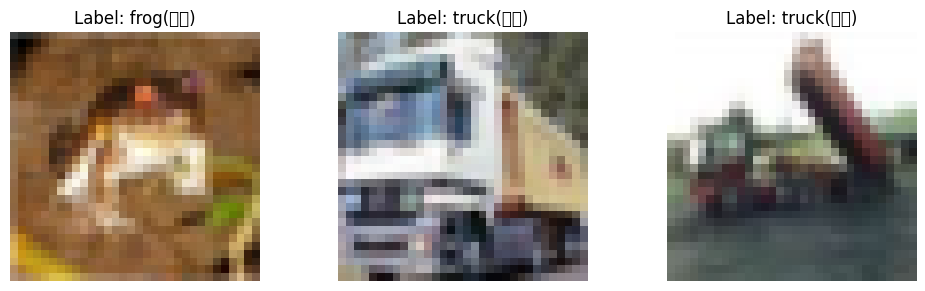

In [11]:
# 呈現訓練資料
plt.figure(figsize=(10, 3))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(x_train[i])
    label_index = np.argmax(y_train[i])
    plt.title(f"Label: {labels_name[label_index]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

## b. 建立神經網路模型

In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.layers import Dropout

In [13]:
model = Sequential()

In [14]:
# 第一層：卷積層16個Filter，尺寸大小(3,3)
model.add(Conv2D(32, (5, 5), padding='same',
        input_shape=(32, 32, 3),
        activation='relu')) # 參數個數: 32 * (5*5*3+1) = 2432

# 第二層：dropout
model.add(Dropout(0.25))

# 第三層：池化層，池化尺寸(2,2)
model.add(MaxPool2D())

# 第四層：卷積層32個Filter，尺寸大小(3,3)
model.add(Conv2D(64, (3, 3), padding='same',
        activation='relu')) # 參數個數: 64 * (3*3*32+1) = 18496

# 第五層：dropout
model.add(Dropout(0.25))

# 第六層：池化層，池化尺寸(2,2)
model.add(MaxPool2D())

# 第七層：拉平層
model.add(Flatten())

# 第八層：dropout
model.add(Dropout(0.25))

# 第九層：全連接層：1024個神經元
model.add(Dense(1024, activation='relu')) # 參數個數: 4096 * 1024 + 1024 = 4195328

# 第十層：dropout
model.add(Dropout(0.25))

# 第十一層：全連接層：10個神經元
model.add(Dense(10, activation='softmax')) # 參數個數: 1024 * 10 + 10 = 10250

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     4,195,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,226,506 (16.12 MB)

 Trainable params: 4,226,506 (16.12 MB)

 Non-trainable params: 0 (0.00 B)

## c. 訓練神經網路模型

In [15]:
model.compile(loss='categorical_crossentropy',
      optimizer=Adam(learning_rate=0.001),
      metrics=['accuracy'])

In [16]:
# 訓練資料中切出20%為驗證資料
train_history = model.fit(x_train, y_train, validation_split=0.2, batch_size=128, epochs=20)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 152s 478ms/step - accuracy: 0.4429 - loss: 1.5536 - val_accuracy: 0.5438 - val_loss: 1.3587
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 145s 464ms/step - accuracy: 0.5696 - loss: 1.2045 - val_accuracy: 0.6064 - val_loss: 1.1814
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 199s 454ms/step - accuracy: 0.6242 - loss: 1.0616 - val_accuracy: 0.6350 - val_loss: 1.1157
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 206s 469ms/step - accuracy: 0.6683 - loss: 0.9431 - val_accuracy: 0.6774 - val_loss: 0.9949
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 198s 456ms/step - accuracy: 0.7078 - loss: 0.8357 - val_accuracy: 0.6746 - val_loss: 0.9564
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 201s 454ms/step - accuracy: 0.7387 - loss: 0.7429 - val_accuracy: 0.6912 - val_loss: 0.9157
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 204s 460ms/step - accuracy: 0.7685 - loss: 0.6561 - val_accuracy: 0.7087 - val_loss: 0.8693
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 201s 458ms/step - accuracy: 0.8011 -

## d. 以折線圖顯示訓練過程的 loss & accuracy

In [17]:
import matplotlib.pyplot as plt

# 畫出訓練過程每一個epoch訓練資料與驗證資料各自準確率(accuracy)的變化，或者損失誤差(loss)的變化
def show_train_history(train_history,train,validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

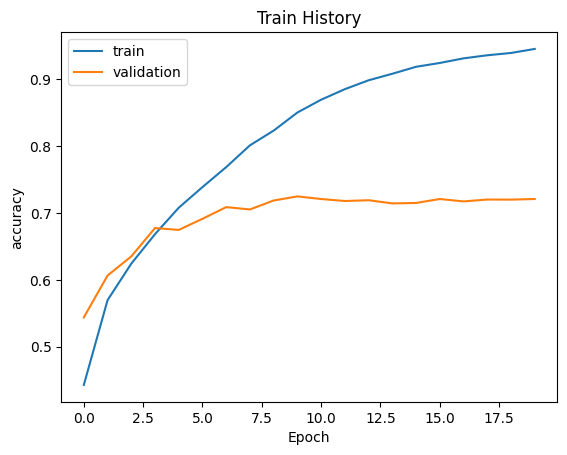

In [18]:
# 準確率(accuracy)
show_train_history(train_history,'accuracy','val_accuracy')

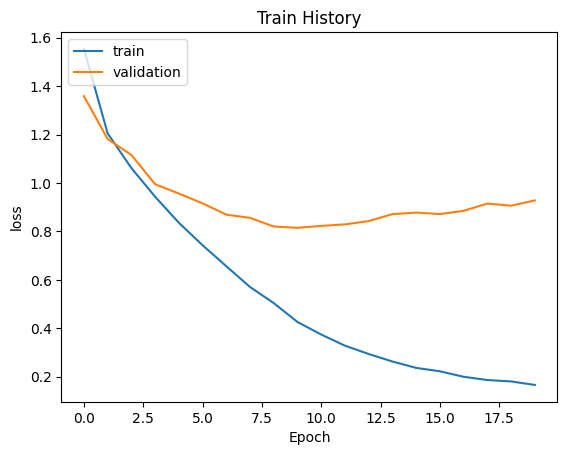

In [19]:
# 損失誤差(loss)
show_train_history(train_history,'loss','val_loss')

## e. 評估模型準確率

In [20]:
scores = model.evaluate(x_test, y_test)
print()
print('accuracy=',scores[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.7219 - loss: 0.9183

accuracy= 0.7218999862670898


## f. 進行預測

In [21]:
# 一次呈現數張測試資料(圖片)、預測結果與真實結果
def plot_images_labels_prediction(images, labels_onehot, prediction, idx, num=10):
    fig = plt.gcf()
    fig.set_size_inches(12, 14)
    if num > 25: num = 25

    labels = np.argmax(labels_onehot, axis=1)
    pred_labels = np.argmax(prediction, axis=1)

    for i in range(0, num):
        ax = plt.subplot(5, 5, 1 + i)
        ax.imshow(images[idx])

        title = "label=" + str(labels_name[labels[idx]]) + "\n"
        title += "predict=" + str(labels_name[pred_labels[idx]])

        ax.set_title(title, fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        idx += 1
    plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 35987 (\N{CJK UNIFIED IDEOGRAPH-8C93}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 33337 (\N{CJK UNIFIED IDEOGRAPH-8239}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 27773 (\N{CJK UNIFIED IDEOGRAPH-6C7D}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 39131 (\N{CJK UNIFIED IDEOGRAPH-98DB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 27231 (\N{CJK UNIFIED IDEOGRAPH-6A5F}) missing from font(s) DejaVu Sans.
  fig.canvas

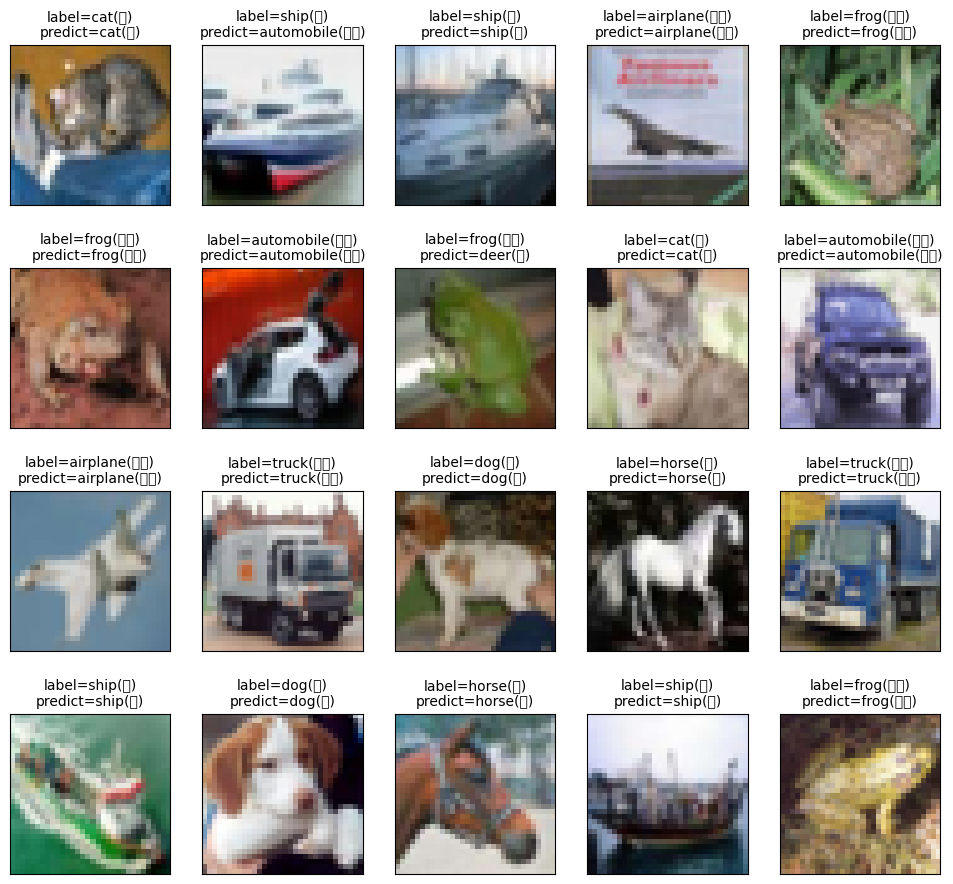

In [22]:
prediction = model.predict(x_test)
plot_images_labels_prediction(x_test,y_test,prediction,idx=0,num=20)

## g. 以混淆矩陣(Confusion matrix)呈現預測結果

In [23]:
import pandas as pd

# 把 one-hot y_test 轉換為整數標籤
true_labels = np.argmax(y_test, axis=1)

# 將10000個預測結果一一轉換為
predicted_labels = np.argmax(prediction, axis=1)

# Now use predicted_labels in crosstab
pd.crosstab(true_labels, predicted_labels, rownames=['label'], colnames=['predict'])

predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,745,18,69,14,23,3,23,15,53,37
1,26,844,4,9,6,4,16,2,18,71
2,41,4,595,49,125,53,82,30,17,4
3,15,12,67,462,114,161,98,47,12,12
4,12,6,47,37,772,19,54,41,8,4
5,11,5,36,155,84,598,49,52,1,9
6,4,3,33,42,48,24,829,5,5,7
7,10,2,19,29,94,43,12,783,2,6
8,55,40,13,17,17,7,11,5,803,32


##　h. 儲存完整模型

In [25]:
#儲存 model
from google.colab import drive
drive.mount('/content/drive')

%cd '/content/drive/My Drive/Colab Notebooks'

model.save('hw4-2.keras')

Mounted at /content/drive
/content/drive/My Drive/Colab Notebooks


##　i. interact_manual

In [26]:
y_predict = np.argmax(prediction, axis=1)

from ipywidgets import interact_manual
def test(test):
  plt.imshow(x_test[test], cmap='Greys')
  print('神經網路判斷為：', str(labels_name[y_predict[test]]))